<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## ⏸️ Human-in-the-loop 与 Time Travel

**一句话定位**：一切靠 **checkpointer + thread_id**。暂停用 `interrupt()`、续跑用 `Command(resume=…)`；改历史用 `update_state`；回到过去用 `get_state_history` + checkpoint config。
> 覆盖 module-3 全部；本机 langgraph 1.2 实测。课件的 `interrupt_before` / `update_state(as_node=…)` / `NodeInterrupt` 是老写法，这里给出新旧对照。

</div>

### 1️⃣ 三种暂停方式对照

| | `interrupt()` 🆕 推荐 | `interrupt_before/after=[节点]` | `NodeInterrupt` |
|---|---|---|---|
| 在哪写 | 节点函数内 | `compile()` 或 `stream()` 参数 | 节点内 `raise` |
| 何时停 | 运行时按条件 | 每次到该节点前/后 | 运行时按条件 |
| 能带信息给人？ | ✅ payload | ❌ | ✅ 消息 |
| 能拿到人的回复？ | ✅ `interrupt()` 返回值 | ❌（靠 `update_state` 改 state） | ❌ |
| 续跑 | `invoke(Command(resume=x), cfg)` | `invoke(None, cfg)` | 改 state 后 `invoke(None, cfg)` |
| 状态 | 官方 HITL 标准 | 官方：调试工具，不推荐做 HITL | 1.0 弃用，2.0 移除 |

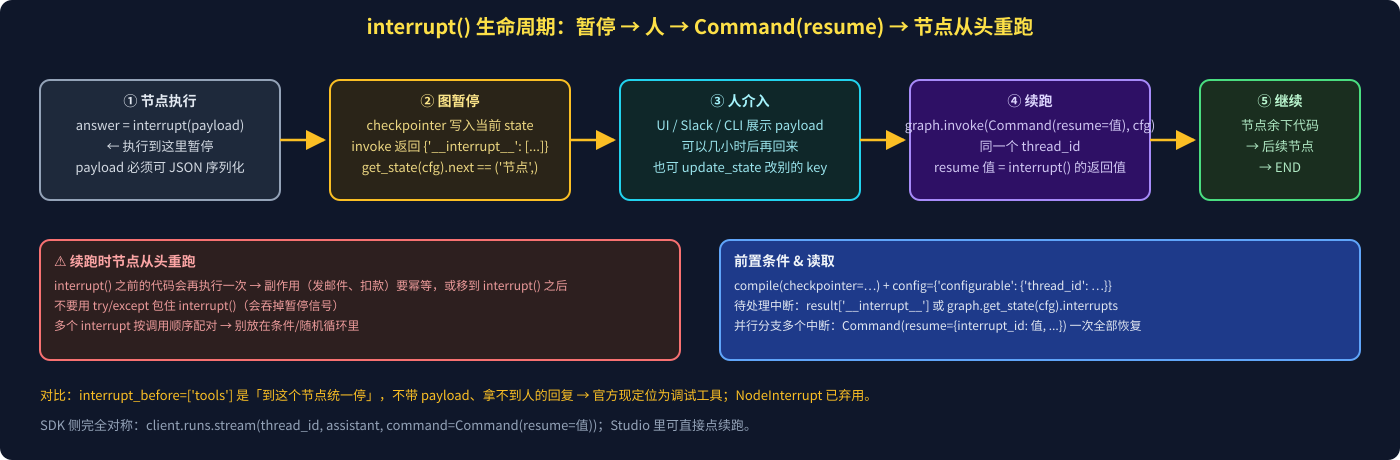

In [ ]:
from IPython.display import SVG
SVG(filename="assets/09_interrupt_lifecycle.svg")

### 2️⃣ 标准模板：审批 / 修改 / 拒绝一次工具调用

In [ ]:
# 前置：本节代码共用的对象（builder 里的 assistant / tools / human_review 节点见 笔记/03、module-3）
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, MessagesState

builder = StateGraph(MessagesState)
memory = InMemorySaver()
inputs = {"messages": [HumanMessage("Multiply 2 and 3")]}

In [ ]:
from typing import Literal
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

def human_review(state) -> Command[Literal["tools", "assistant"]]:
    tool_call = state["messages"][-1].tool_calls[0]
    decision = interrupt({                         # ① 暂停，payload 给 UI
        "question": "执行这个 tool 吗？",
        "tool_call": tool_call,
        "options": ["approve", "edit", "reject"],
    })
    if decision["action"] == "approve":            # ② resume 的值在这里被拿到
        return Command(goto="tools")
    if decision["action"] == "edit":               # 覆盖同 id 的 AIMessage，改参数后再执行
        new_ai = state["messages"][-1].model_copy(update={"tool_calls": [decision["tool_call"]]})
        return Command(goto="tools", update={"messages": [new_ai]})
    return Command(goto="assistant", update={"messages": [                     # reject：告诉模型被拒
        {"role": "tool", "content": decision["reason"], "tool_call_id": tool_call["id"]}]})

graph = builder.compile(checkpointer=InMemorySaver())
cfg = {"configurable": {"thread_id": "1"}}

result = graph.invoke({"messages": [("human", "Multiply 2 and 3")]}, cfg)
result["__interrupt__"][0].value                   # → 上面的 payload
graph.invoke(Command(resume={"action": "approve"}), cfg)   # ③ 续跑

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**续跑规则（易错）**
1. 节点**从头重跑**到 `interrupt()`：之前的副作用要幂等，或放到 `interrupt()` 之后。
2. 别 `try/except` 包 `interrupt()`。
3. 一个节点多个 `interrupt()` 按顺序配对——不要放进条件分支或非确定性循环。
4. 续聊用普通 input，不要把 `Command(update=…)` 当输入传给已结束的图（会"卡住"）。
5. `create_agent` 用户：`middleware=[HumanInTheLoopMiddleware(interrupt_on={"send_email": True})]` 一行搞定工具审批。

</div>

### 3️⃣ 静态断点（调试仍好用）

In [ ]:
graph = builder.compile(checkpointer=memory, interrupt_before=["tools"])   # 或 interrupt_after
for ev in graph.stream(inputs, cfg, stream_mode="values"): ...                # 停在 tools 前
graph.get_state(cfg).next        # ('tools',)
graph.stream(None, cfg)          # None = 从当前 checkpoint 继续
# SDK：client.runs.stream(tid, "agent", input=..., interrupt_before=["tools"])  运行时指定，不用改代码

### 4️⃣ 编辑 state：`update_state`

```python
graph.update_state(cfg, {"messages": [HumanMessage("改成 3 乘 3", id=old_id)]})   # 带 id = 覆盖；不带 = 追加（走 add_messages）
graph.update_state(cfg, {"feedback": "..."}, as_node="human_feedback")           # 冒充某节点写入 → 下一跳按该节点的出边走
```

| 用途 | 现在推荐 |
|---|---|
| 接收人工反馈 | `interrupt()` 返回值（不再需要空节点 + `as_node`） |
| 调试时手改 state | `update_state` ✅ |
| 分叉历史 | `update_state(历史 checkpoint 的 config, …)` ✅ |

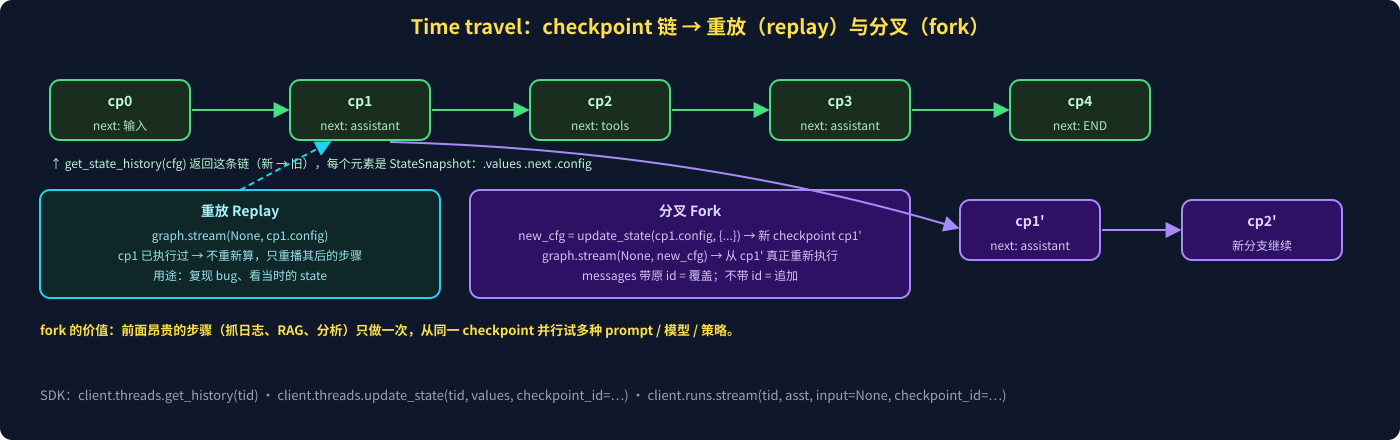

In [ ]:
from IPython.display import SVG
SVG(filename="assets/09_time_travel.svg")

### 5️⃣ Time travel 三动作

In [ ]:
# 浏览
graph.get_state(cfg)                                   # 当前 StateSnapshot：.values .next .config .tasks .interrupts
history = list(graph.get_state_history(cfg))           # 全部 checkpoint，新 → 旧
snap = history[-2]                                     # 比如：刚收到 human 输入那一步
snap.config["configurable"]["checkpoint_id"]

# 重放：传已执行过的 checkpoint config → 不重新计算
for ev in graph.stream(None, snap.config, stream_mode="values"): ...

# 分叉：先改，再从新 checkpoint 跑
fork_cfg = graph.update_state(snap.config,
    {"messages": [HumanMessage("Multiply 5 and 3", id=snap.values["messages"][0].id)]})
for ev in graph.stream(None, fork_cfg, stream_mode="values"): ...        # 真正重新执行

### 6️⃣ 本地 ↔ SDK 对照

| 本地 | SDK |
|---|---|
| `graph.get_state(cfg)` | `await client.threads.get_state(tid)` |
| `graph.get_state_history(cfg)` | `await client.threads.get_history(tid)`（list[dict]，`['checkpoint_id']`） |
| `graph.update_state(cfg, v)` | `await client.threads.update_state(tid, v, checkpoint_id=…)` |
| `graph.stream(None, cfg)` | `client.runs.stream(tid, asst, input=None, checkpoint_id=…)` |
| `graph.invoke(Command(resume=x), cfg)` | `client.runs.stream(tid, asst, command=Command(resume=x))` |
| `compile(interrupt_before=…)` | `runs.stream(..., interrupt_before=[…])` |
| — | `client.threads.copy(tid)`：整条 thread 复制一份再实验 |

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：**`interrupt(payload)` 暂停、`Command(resume=值)` 续跑、节点从头重跑**；`update_state` 改 state（messages 带 id 覆盖）；`get_state_history` 拿到任意 checkpoint，传回去 = 重放，先 `update_state` 再传回去 = 分叉。全部依赖 checkpointer + thread_id，SDK 一一对应。

</div>